# Clustering Track — Credit Card Customer Segmentation
**23CSE301 Machine Learning Capstone — Review 2**

Pipeline: load & audit → EDA → cleaning & scaling → **K-Means** (Elbow) → **Agglomerative Hierarchical** (Dendrogram, linkage comparison) → Silhouette / Davies-Bouldin / Calinski-Harabasz → PCA & t-SNE visualisation → cluster profiling.

Clustering is unsupervised: there is no target column, and nothing here is evaluated against labels.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
sns.set_style('whitegrid')
sns.set_palette('colorblind')
plt.rcParams['figure.figsize'] = (8, 5)

## 1. Dataset loading & audit

In [2]:
DATA_PATH = "../data/CC GENERAL.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [3]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


In [4]:
missing = df.isnull().sum()
missing = missing[missing > 0]
print("Missing values:\n", missing if len(missing) else "None")
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate CUST_IDs:", df['CUST_ID'].duplicated().sum())

Missing values:
 CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

Duplicate rows: 0
Duplicate CUST_IDs: 0


## 2. EDA

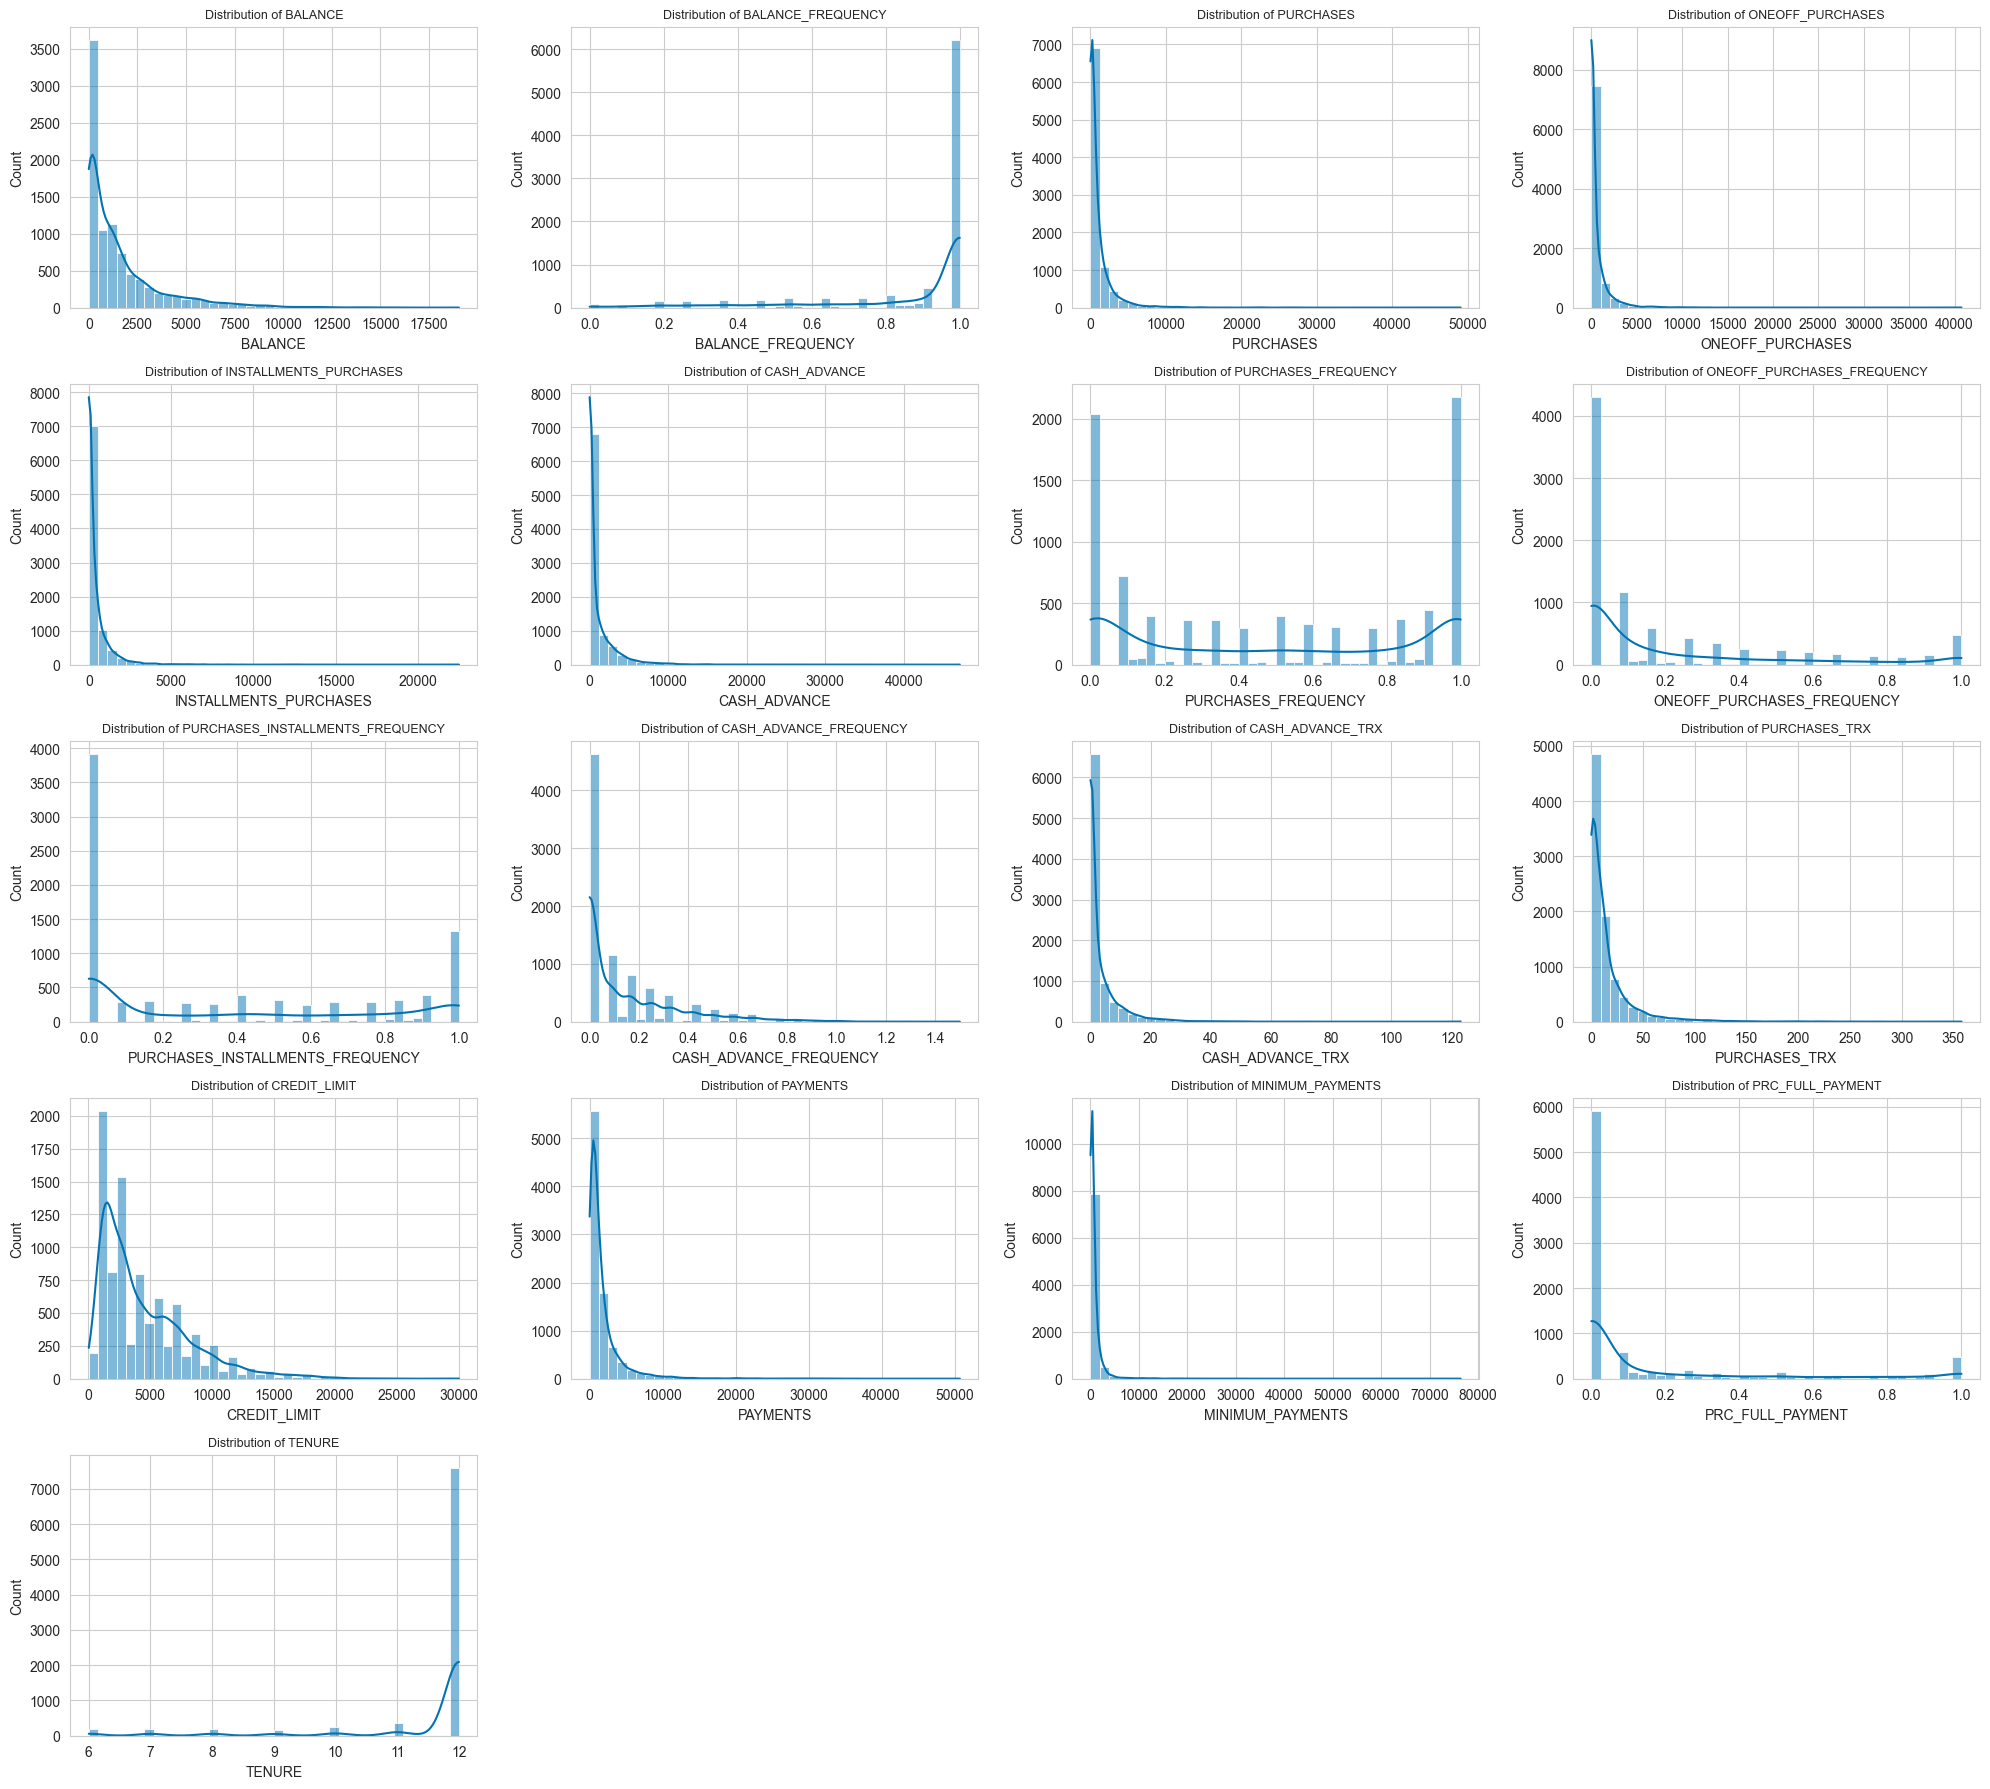

In [5]:
features = [col for col in df.columns if col != 'CUST_ID']

fig, axes = plt.subplots(5, 4, figsize=(20, 18))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.histplot(df[col].dropna(), bins=40, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}', fontsize=9)
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout(); plt.show()

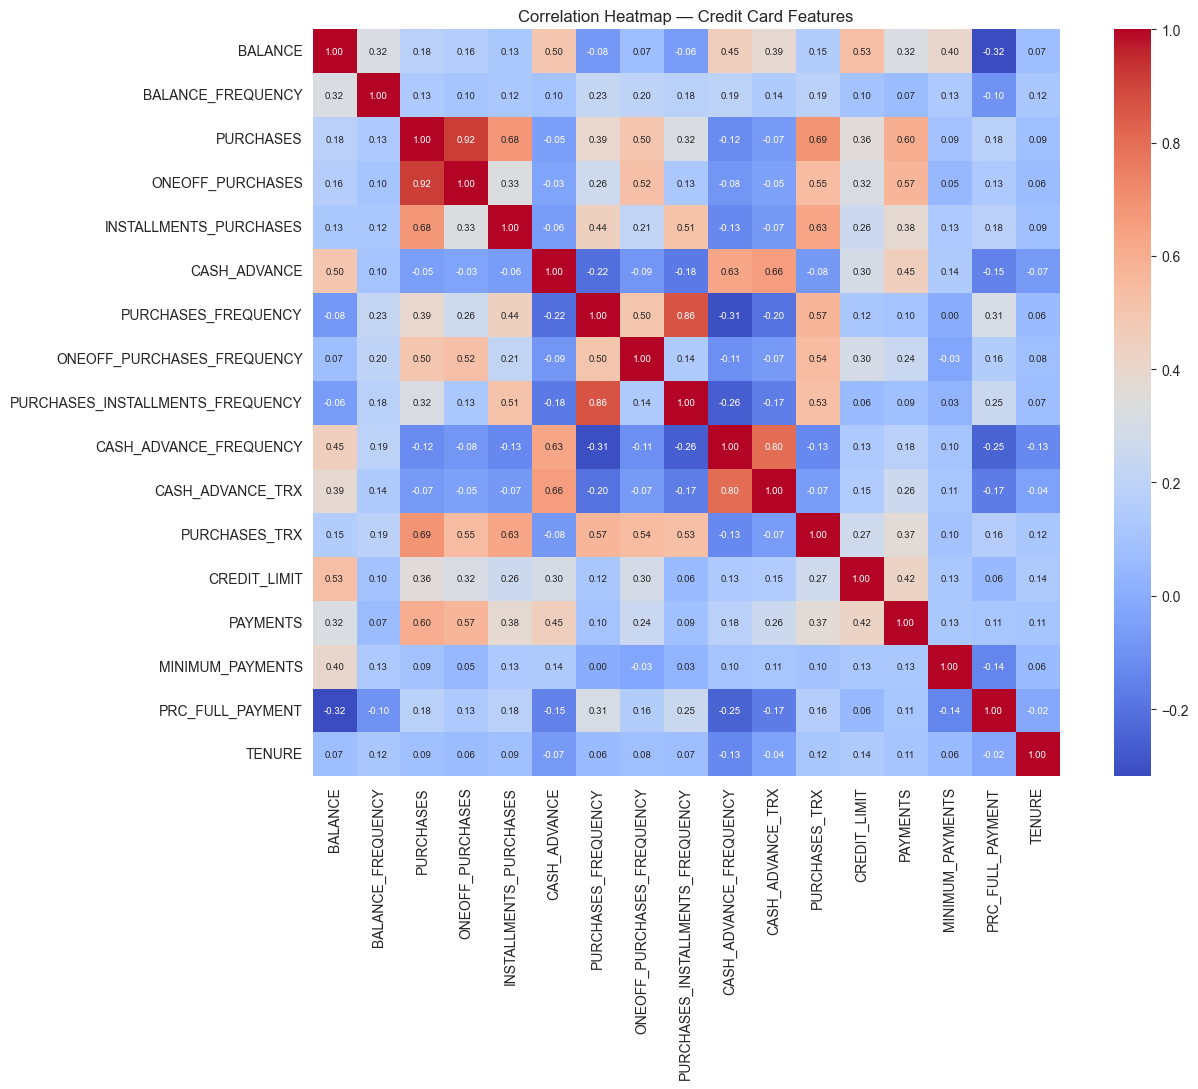

In [6]:
plt.figure(figsize=(14, 11))
sns.heatmap(df[features].corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True, annot_kws={'size': 7})
plt.title('Correlation Heatmap — Credit Card Features')
plt.tight_layout(); plt.show()

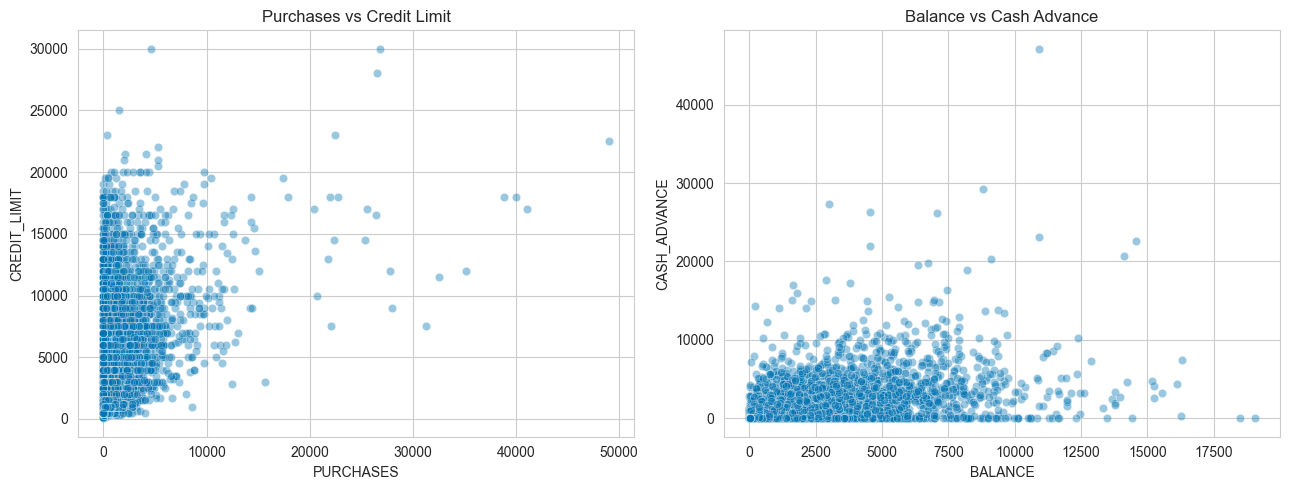

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=df, x='PURCHASES', y='CREDIT_LIMIT', alpha=0.4, ax=axes[0])
axes[0].set_title('Purchases vs Credit Limit')
sns.scatterplot(data=df, x='BALANCE', y='CASH_ADVANCE', alpha=0.4, ax=axes[1])
axes[1].set_title('Balance vs Cash Advance')
plt.tight_layout(); plt.show()

> **Observations (write your own):** note the heavy right-skew in monetary columns, the strong correlations (e.g. PURCHASES vs ONEOFF_PURCHASES, PURCHASES_FREQUENCY vs PURCHASES_INSTALLMENTS_FREQUENCY), and what these imply for distance-based clustering.

## 3. Preprocessing
- Drop `CUST_ID` (identifier, no information).
- Impute missing `MINIMUM_PAYMENTS` and `CREDIT_LIMIT` with the **median** (columns are heavily skewed, so the mean would be pulled by outliers).
- Apply `log1p` to the skewed monetary / count columns so that a few extreme customers do not dominate Euclidean distances. Frequency columns (0–1) and TENURE are left as is.
- Standardise all features (`StandardScaler`) — K-Means and Ward linkage are both distance based. There is no train/test split in unsupervised clustering, so scaling on the full dataset is not leakage.

In [8]:
data = df.drop(columns=['CUST_ID']).copy()
df_before = data.copy()                       # keep original-scale copy for profiling

imputer = SimpleImputer(strategy='median')
data[:] = imputer.fit_transform(data)

skewed_cols = ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE',
               'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS']
print("Skewness before log1p:\n", data[skewed_cols].skew().round(2).to_string())
data[skewed_cols] = np.log1p(data[skewed_cols])
print("\nSkewness after log1p:\n", data[skewed_cols].skew().round(2).to_string())

Skewness before log1p:
 BALANCE                    2.39
PURCHASES                  8.14
ONEOFF_PURCHASES          10.05
INSTALLMENTS_PURCHASES     7.30
CASH_ADVANCE               5.17
CASH_ADVANCE_TRX           5.72
PURCHASES_TRX              4.63
CREDIT_LIMIT               1.52
PAYMENTS                   5.91
MINIMUM_PAYMENTS          13.85

Skewness after log1p:
 BALANCE                  -0.86
PURCHASES                -0.76
ONEOFF_PURCHASES          0.19
INSTALLMENTS_PURCHASES   -0.02
CASH_ADVANCE              0.26
CASH_ADVANCE_TRX          0.94
PURCHASES_TRX             0.03
CREDIT_LIMIT             -0.10
PAYMENTS                 -1.78
MINIMUM_PAYMENTS          0.27


### Feature engineering

In [9]:
# Engineered feature: payment-to-balance behaviour. A customer who pays far more than the
# balance they carry behaves very differently from one who revolves a balance.
raw = df_before.fillna(df_before.median())
data['PAYMENT_TO_BALANCE'] = np.log1p(raw['PAYMENTS'] / (raw['BALANCE'] + 1))

scaler = StandardScaler()
X = scaler.fit_transform(data)
X_df = pd.DataFrame(X, columns=data.columns)
print("Final feature matrix:", X.shape)

Final feature matrix: (8950, 18)


In [10]:
# Helper to compute the 3 mandatory internal metrics
def cluster_metrics(X, labels):
    return {'Silhouette': silhouette_score(X, labels),
            'Davies-Bouldin': davies_bouldin_score(X, labels),
            'Calinski-Harabasz': calinski_harabasz_score(X, labels)}

## 4. K-Means Clustering
### 4.1 Elbow curve (and silhouette) to choose k

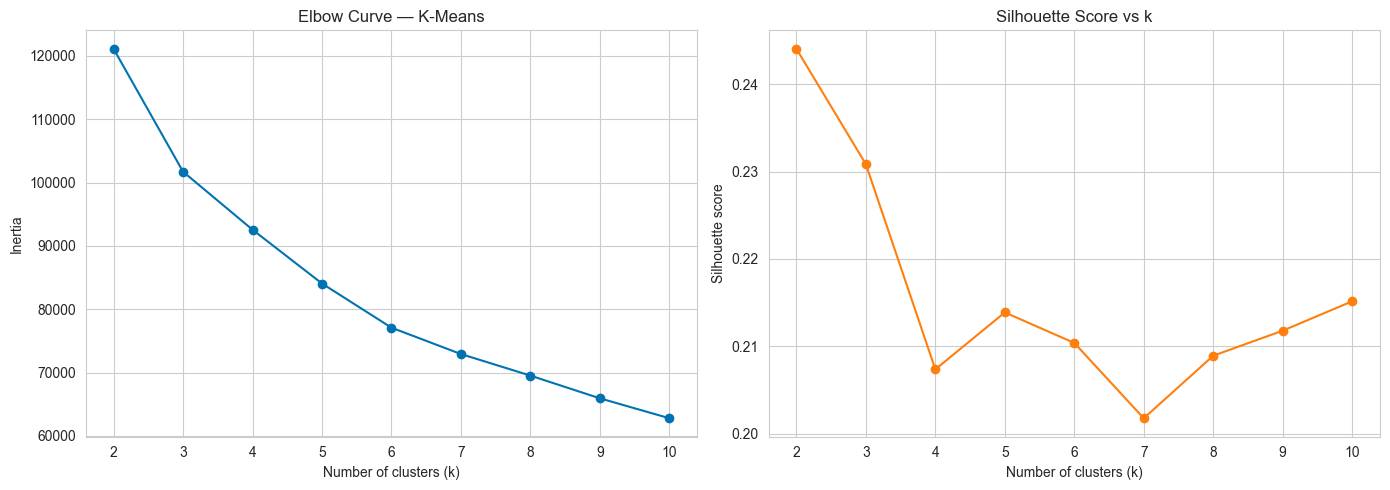

,k,Inertia,Silhouette
0,2,121112.264742,0.244036
1,3,101712.166030,0.230839
2,4,92552.576895,0.207378
3,5,84058.592939,0.213888
4,6,77084.661176,0.210399
5,7,72923.570442,0.201787
6,8,69518.216857,0.208940
7,9,65931.499307,0.211802
8,10,62787.536196,0.215163


In [21]:
K_RANGE = range(2, 11)
inertias, sil_scores = [], []

for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, km.labels_))
    
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(K_RANGE), inertias, 'o-')
axes[0].set_title('Elbow Curve — K-Means'); axes[0].set_xlabel('Number of clusters (k)'); axes[0].set_ylabel('Inertia')
axes[1].plot(list(K_RANGE), sil_scores, 'o-', color='tab:orange')
axes[1].set_title('Silhouette Score vs k'); axes[1].set_xlabel('Number of clusters (k)'); axes[1].set_ylabel('Silhouette score')
plt.tight_layout(); plt.show()
pd.DataFrame({'k': list(K_RANGE), 'Inertia': inertias, 'Silhouette': sil_scores})

> **Choosing k (write your own justification):** point to where the elbow bends and what the silhouette says, then set `K_CHOSEN` below.

In [12]:
K_CHOSEN = 4        # <-- set from the elbow / silhouette plots above
kmeans = KMeans(n_clusters=K_CHOSEN, n_init=10, random_state=RANDOM_STATE).fit(X)
km_labels = kmeans.labels_
print("K-Means cluster sizes:\n", pd.Series(km_labels).value_counts().sort_index().to_string())

K-Means cluster sizes:
 0    2060
1    1456
2    2630
3    2804


## 5. Agglomerative Hierarchical Clustering
### 5.1 Dendrogram

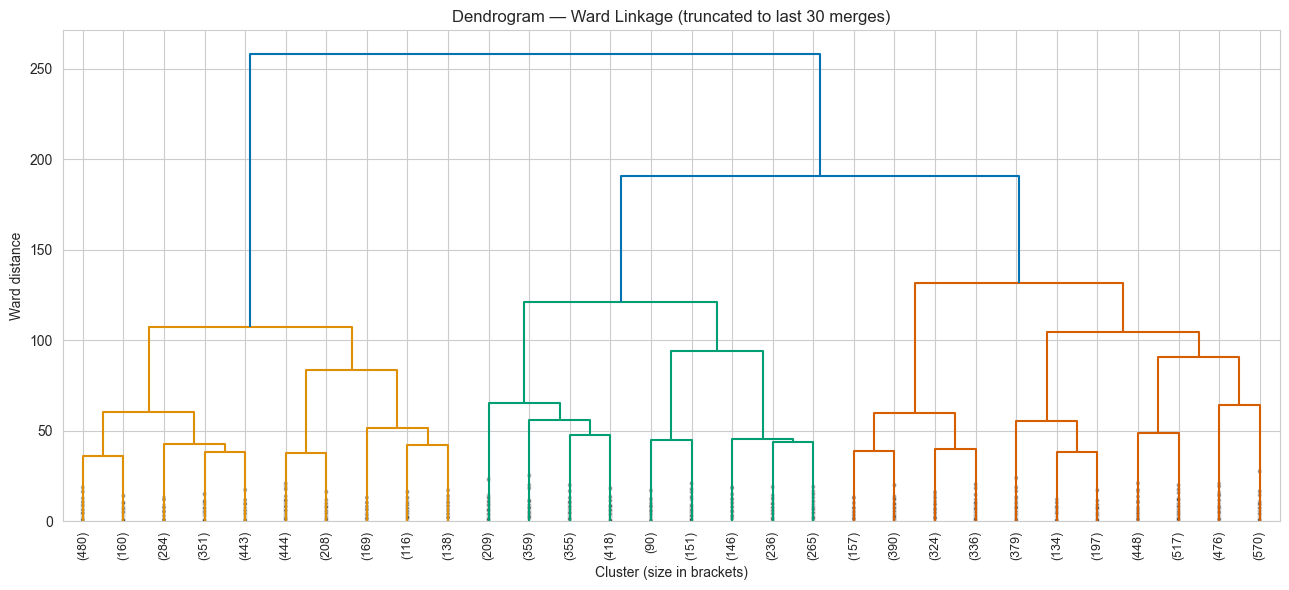

In [13]:
Z = linkage(X, method='ward')
plt.figure(figsize=(13, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True)
plt.title('Dendrogram — Ward Linkage (truncated to last 30 merges)')
plt.xlabel('Cluster (size in brackets)'); plt.ylabel('Ward distance')
plt.tight_layout(); plt.show()

### 5.2 Linkage strategy comparison

In [14]:
linkage_rows = {}
for link in ['ward', 'complete', 'average', 'single']:
    lab = AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=link).fit_predict(X)
    linkage_rows[link] = cluster_metrics(X, lab)
linkage_df = pd.DataFrame(linkage_rows).T
display(linkage_df.style.format('{:.4f}'))
print("Smallest cluster size per linkage:")
for link in linkage_rows:
    sizes = pd.Series(AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=link).fit_predict(X)).value_counts()
    print(f"  {link:9s}", sizes.to_dict())

,Silhouette,Davies-Bouldin,Calinski-Harabasz
ward,0.1644,1.8498,1782.7170
complete,0.0727,1.7315,675.6837
average,0.1267,1.3459,124.0217
single,0.1887,0.5819,2.9203


Smallest cluster size per linkage:
  ward      {1: 2793, 2: 2721, 0: 2229, 3: 1207}
  complete  {0: 7067, 1: 821, 3: 574, 2: 488}
  average   {3: 8689, 1: 247, 0: 13, 2: 1}
  single    {0: 8947, 3: 1, 2: 1, 1: 1}


> **Observation (write your own):** single/average linkage often give one giant cluster plus tiny ones (chaining) which can inflate silhouette while being useless as segmentation; compare cluster sizes before choosing the final linkage.

In [15]:
BEST_LINKAGE = 'ward'    # <-- choose using the table and cluster sizes above
agg = AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=BEST_LINKAGE)
agg_labels = agg.fit_predict(X)
print("Agglomerative cluster sizes:\n", pd.Series(agg_labels).value_counts().sort_index().to_string())

Agglomerative cluster sizes:
 0    2229
1    2793
2    2721
3    1207


## 6. Evaluation — Silhouette, Davies-Bouldin, Calinski-Harabasz
Higher is better for Silhouette and Calinski-Harabasz; **lower** is better for Davies-Bouldin.

In [16]:
eval_df = pd.DataFrame({
    'K-Means': cluster_metrics(X, km_labels),
    f'Agglomerative ({BEST_LINKAGE})': cluster_metrics(X, agg_labels),
}).T
eval_df['n_clusters'] = [K_CHOSEN, K_CHOSEN]
display(eval_df.style.format({'Silhouette': '{:.4f}', 'Davies-Bouldin': '{:.4f}', 'Calinski-Harabasz': '{:.1f}'}))
print("Agreement between the two clusterings (Adjusted Rand Index): %.4f" % adjusted_rand_score(km_labels, agg_labels))

,Silhouette,Davies-Bouldin,Calinski-Harabasz,n_clusters
K-Means,0.2074,1.6993,2208.6,4
Agglomerative (ward),0.1644,1.8498,1782.7,4


Agreement between the two clusterings (Adjusted Rand Index): 0.6098


## 7. Cluster visualisation
### 7.1 PCA (2 components)

Explained variance ratio: [0.33  0.222] | total: 55.1%


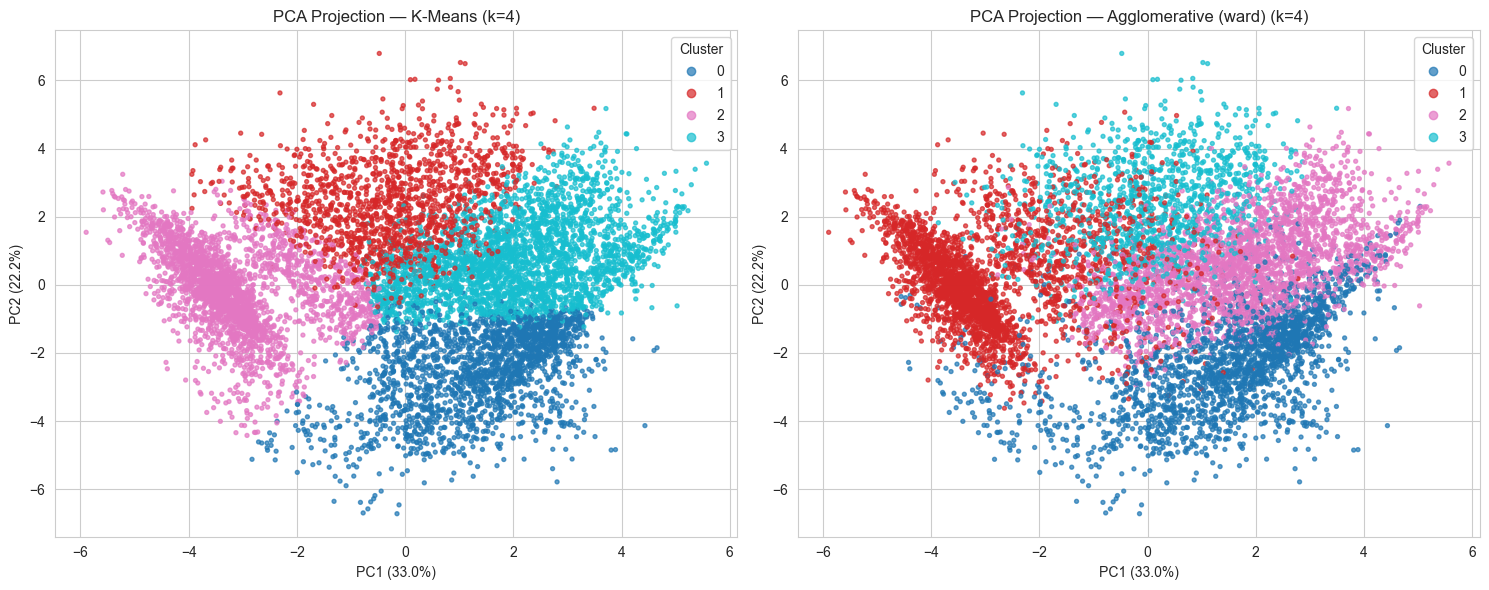

In [17]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3),
      "| total: %.1f%%" % (100 * pca.explained_variance_ratio_.sum()))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, labels, title in zip(axes, [km_labels, agg_labels],
                             ['K-Means', f'Agglomerative ({BEST_LINKAGE})']):
    sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='tab10', s=8, alpha=0.7)
    ax.set_title(f'PCA Projection — {title} (k={K_CHOSEN})')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.legend(*sc.legend_elements(), title='Cluster', loc='best')
plt.tight_layout(); plt.show()

### 7.2 t-SNE (K-Means labels)

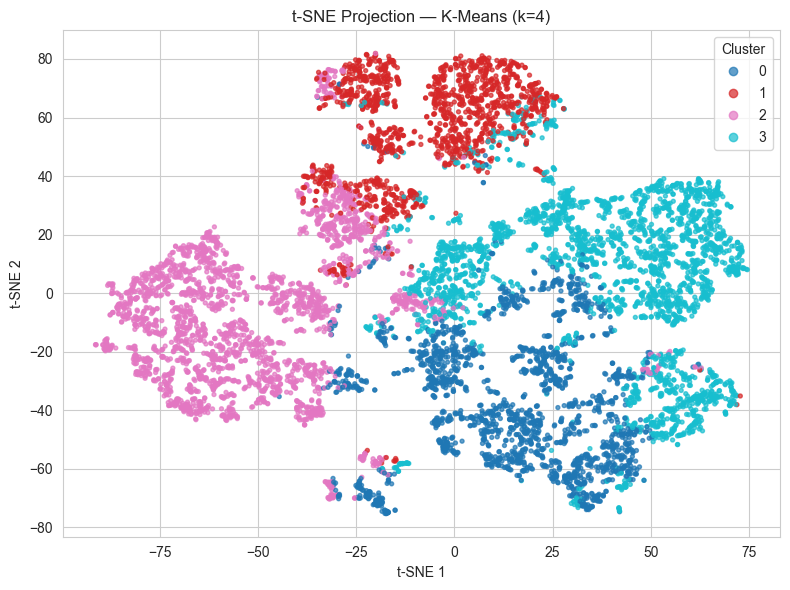

In [18]:
tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X)

plt.figure(figsize=(8, 6))
sc = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=km_labels, cmap='tab10', s=8, alpha=0.7)
plt.title(f't-SNE Projection — K-Means (k={K_CHOSEN})')
plt.xlabel('t-SNE 1'); plt.ylabel('t-SNE 2')
plt.legend(*sc.legend_elements(), title='Cluster', loc='best')
plt.tight_layout(); plt.show()

## 8. Cluster profiling
Profiles use the **original-scale** values (missing values median-filled) so the segments can be interpreted in business terms.

KMeans_Cluster,0,1,2,3
BALANCE,57.35,3258.37,2123.88,1267.44
BALANCE_FREQUENCY,0.62,0.98,0.92,0.98
PURCHASES,425.21,1435.71,46.11,2100.96
ONEOFF_PURCHASES,135.89,855.43,42.76,1306.85
INSTALLMENTS_PURCHASES,289.85,580.50,3.40,794.52
CASH_ADVANCE,44.26,2569.48,1842.95,29.10
PURCHASES_FREQUENCY,0.53,0.70,0.03,0.79
ONEOFF_PURCHASES_FREQUENCY,0.06,0.30,0.03,0.42
PURCHASES_INSTALLMENTS_FREQUENCY,0.44,0.51,0.01,0.57
CASH_ADVANCE_FREQUENCY,0.01,0.34,0.26,0.01


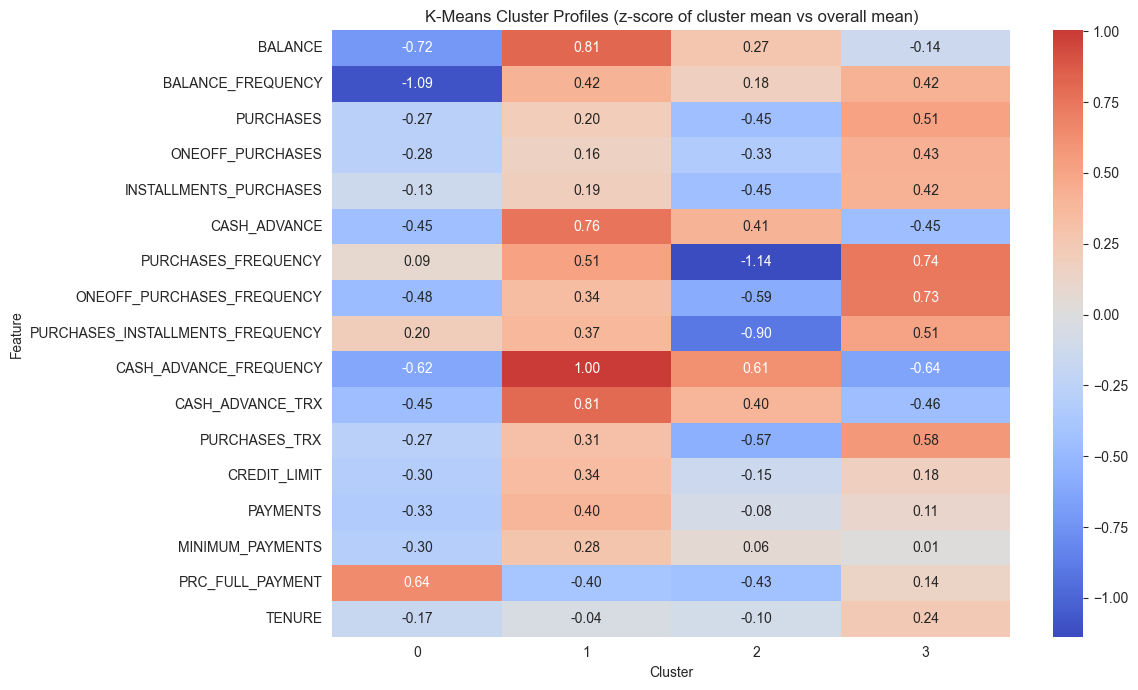

In [19]:
profile = raw.copy()
profile['KMeans_Cluster'] = km_labels
prof_mean = profile.groupby('KMeans_Cluster').mean()
prof_mean['Size'] = profile['KMeans_Cluster'].value_counts().sort_index()
display(prof_mean.round(2).T)

# Standardised heatmap makes the differences between clusters easy to read
z = (prof_mean.drop(columns='Size') - profile.drop(columns='KMeans_Cluster').mean()) / profile.drop(columns='KMeans_Cluster').std()
plt.figure(figsize=(12, 7))
sns.heatmap(z.T, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('K-Means Cluster Profiles (z-score of cluster mean vs overall mean)')
plt.xlabel('Cluster'); plt.ylabel('Feature')
plt.tight_layout(); plt.show()

> **Segment interpretation (write your own):** name each cluster (e.g. big spenders, cash-advance users, low-activity customers) from the heatmap and say what a bank could do with each segment.

## 9. Conclusion
Summarise: chosen k and why, K-Means vs Agglomerative on the three metrics, limitations (metric disagreement, PCA explained variance, sensitivity to log-transform/scaling), and possible next steps (DBSCAN / Gaussian Mixture).